# TPI - Entrega 4: Analisis Exploratorio de Datos (Comparaciones)
## Comision 13 (Grupo M) | Integrante: Gustavo Farias

**Lenguaje utilizado:** Python (pandas, matplotlib, seaborn) para el entorno y las visualizaciones; SQL (DuckDB) para todas las consultas.
**Dataset:** reservas hoteleras (City Hotel y Resort Hotel), archivo `hotel booking TPI grupo M.csv`.
**Problema:** comprender las cancelaciones de reservas (`is_canceled`) para reducir su tasa y mejorar la planificacion.
**Variable objetivo:** `is_canceled` (0 = Efectiva, 1 = Cancelada).

**Alcance:** Analisis comparativo para identificar patrones, relaciones y anomalias entre la variable objetivo y otras variables relevantes. Se formulan hipotesis, se validan con datos y se interpretan con prudencia, distinguiendo asociacion de causalidad.

## 1. Preparacion del entorno y carga de datos

Se carga el dataset original y se aplican las transformaciones minimas justificadas en entregas anteriores (imputacion de `children`, unificacion de `country`, parseo de fechas y creacion de variables derivadas) para garantizar la reproducibilidad del analisis.

In [36]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('duckdb') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'duckdb'])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# Cargo el dataset
try:
    df_original = pd.read_csv('hotel booking TPI grupo M.csv')
    print('Dataset cargado:', df_original.shape)
except FileNotFoundError:
    print('Error: no se encontro el archivo CSV.')

df = df_original.copy()

# Preparacion de entregas anteriores
df['children'] = df['children'].fillna(0).astype(int)
df['country'] = df['country'].replace('CN', 'CHN')
df['arrival_date'] = pd.to_datetime(df['arrival_date'], errors='coerce')

# Variables derivadas
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['lead_time_segment'] = pd.cut(
    df['lead_time'],
    bins=[-1, 7, 30, 90, 1000],
    labels=['Ultima hora (0-7)', 'Corto (8-30)', 'Mediano (31-90)', 'Largo (>90)']
)

# Registro en DuckDB
con = duckdb.connect(':memory:')
con.register('reservas_df', df)
con.execute('CREATE OR REPLACE TABLE reservas AS SELECT * FROM reservas_df')
print("Tabla 'reservas' lista para consultas SQL.")

Dataset cargado: (25000, 32)
Tabla 'reservas' lista para consultas SQL.


## 2. Revision del avance (Semana 9)

En la etapa anterior se confirmo la **unidad de analisis** (cada fila es una reserva unica identificada por `booking_id`) y se describieron las distribuciones individuales:
- **is_canceled:** 36,7% de cancelaciones (problema relevante).
- **lead_time:** Fuerte asimetria a la derecha (muchas reservas de ultima hora, cola larga de anticipacion).
- **hotel:** Mayor volumen en City Hotel (66%) vs Resort Hotel (34%).
- **total_nights:** Concentracion en estadias cortas (1-4 noches).

A continuacion, se profundiza en la relacion de estas variables con la cancelacion.

## 3. Hipotesis y Analisis Comparativo

### Hipotesis 1: La anticipacion de la reserva se relaciona con su cancelacion
**Pregunta:** Las reservas canceladas se hicieron con mas dias de antelacion que las efectivas?
**Logica:** A mayor tiempo entre la reserva y la llegada, mayor es la incertidumbre y la probabilidad de que surjan imprevistos.

,is_canceled,n,media,mediana,desvio
0,0,15817,79.1,46.0,89.9
1,1,9183,145.5,113.0,120.0


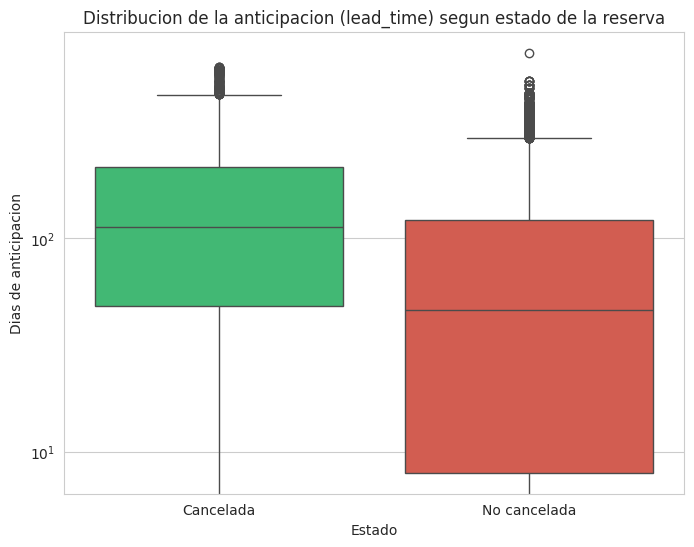

In [37]:
# Consulta SQL: Resumen de lead_time por estado
sql_lead = """
SELECT
    is_canceled,
    COUNT(*) as n,
    ROUND(AVG(lead_time), 1) as media,
    ROUND(MEDIAN(lead_time), 1) as mediana,
    ROUND(STDDEV(lead_time), 1) as desvio
FROM reservas
GROUP BY is_canceled
"""
res_lead = con.sql(sql_lead).df()
display(res_lead)

# Visualizacion: Boxplot
df_plot = df.copy()
df_plot['estado'] = df_plot['is_canceled'].map({0: 'No cancelada', 1: 'Cancelada'})

plt.figure(figsize=(8, 6))
sns.boxplot(data=df_plot, x='estado', y='lead_time', palette=['#2ecc71', '#e74c3c'], hue='estado', legend=False)
plt.title('Distribucion de la anticipacion (lead_time) segun estado de la reserva')
plt.xlabel('Estado')
plt.ylabel('Dias de anticipacion')
plt.yscale('log') # Escala logaritmica para visualizar mejor la cola larga
plt.show()

**Interpretacion:**
La evidencia confirma la hipotesis. Las reservas **canceladas** tienen una mediana de anticipacion significativamente mayor (aprox. 113 dias) comparada con las **no canceladas** (aprox. 46 dias).
- **Patron:** Cuanto mas lejos en el tiempo se hace la reserva, mayor es la tasa de cancelacion.
- **Dispersion:** El grupo de canceladas muestra mucha mas variabilidad y valores extremos (reservas hechas con mas de un año de antelacion).
- **Nota:** Se uso escala logaritmica en el eje Y para poder observar la caja y los bigotes, dado que existen outliers extremos (hasta 737 dias).

### Hipotesis 2: Existen diferencias en la tasa de cancelacion segun el tipo de hotel
**Pregunta:** El perfil urbano (City Hotel) presenta mayor volatilidad que el vacacional (Resort Hotel)?

,hotel,canceladas,total,tasa_cancelacion
0,City Hotel,6874.0,16522,41.6
1,Resort Hotel,2309.0,8478,27.2


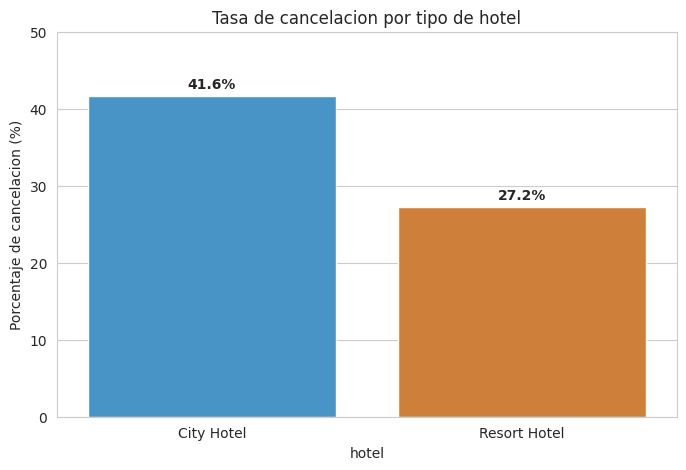

In [38]:
# Consulta SQL: Tasas de cancelacion por hotel
sql_hotel = """
SELECT
    hotel,
    SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END) as canceladas,
    COUNT(*) as total,
    ROUND(100.0 * SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END) / COUNT(*), 1) as tasa_cancelacion
FROM reservas
GROUP BY hotel
ORDER BY hotel
"""
res_hotel = con.sql(sql_hotel).df()
display(res_hotel)

# Visualizacion: Barras agrupadas
plt.figure(figsize=(8, 5))
sns.barplot(data=res_hotel, x='hotel', y='tasa_cancelacion', palette=['#3498db', '#e67e22'], hue='hotel', legend=False)
plt.title('Tasa de cancelacion por tipo de hotel')
plt.ylabel('Porcentaje de cancelacion (%)')
plt.ylim(0, 50)
for i, v in enumerate(res_hotel['tasa_cancelacion']):
    plt.text(i, v + 1, f'{v}%', ha='center', fontweight='bold')
plt.show()

**Interpretacion:**
Existe una diferencia clara en el comportamiento de los clientes segun el tipo de hotel.
- **City Hotel:** Presenta una tasa de cancelacion del **41,6%**.
- **Resort Hotel:** Presenta una tasa menor, del **27,2%**.
- **Analisis:** El perfil de huesped urbano parece tener compromisos mas cambiantes o reservas mas especulativas, mientras que el perfil vacacional (Resort) suele implicar una planificacion mas firme y costosa, lo que reduce la cancelacion.

### Hipotesis 3: El tipo de deposito permite reconocer grupos con comportamientos diferentes
**Pregunta:** Como se comportan las cancelaciones en reservas "No Deposit" vs "Non Refund"?
**Contexto:** Esta variable es critica porque podria estar registrando el *desenlace* de la reserva (penalizacion) y no solo la politica inicial.

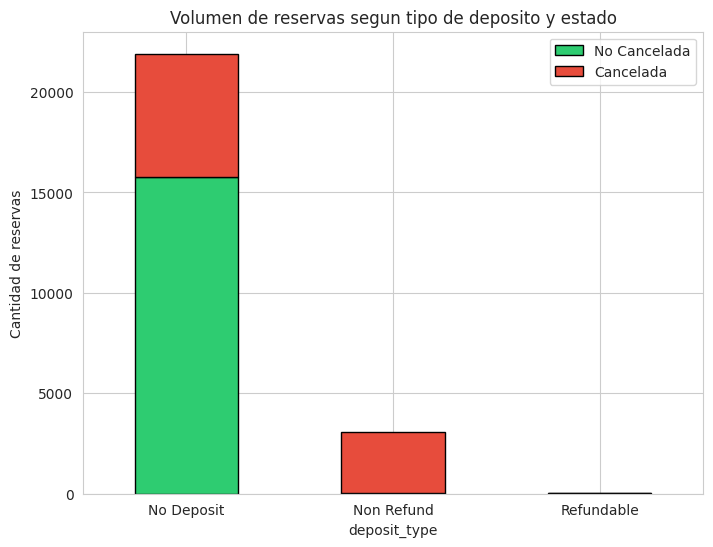

--- Tasa de cancelacion por tipo de deposito ---
No Deposit: 28.0% canceladas (Total: 21912)
Non Refund: 99.3% canceladas (Total: 3051)
Refundable: 24.3% canceladas (Total: 37)


In [39]:
# Consulta SQL: Conteo cruzado de deposito y cancelacion
sql_deposit = """
SELECT
    deposit_type,
    is_canceled,
    COUNT(*) as cantidad
FROM reservas
GROUP BY deposit_type, is_canceled
ORDER BY deposit_type, is_canceled
"""
res_dep = con.sql(sql_deposit).df()

# Pivot para grafico
dep_pivot = res_dep.pivot(index='deposit_type', columns='is_canceled', values='cantidad').fillna(0)
dep_pivot.columns = ['No Cancelada', 'Cancelada']

# Visualizacion: Barras apiladas
dep_pivot.plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], edgecolor='black', figsize=(8, 6))
plt.title('Volumen de reservas segun tipo de deposito y estado')
plt.ylabel('Cantidad de reservas')
plt.xticks(rotation=0)
plt.show()

# Calculo de tasa de cancelacion dentro de cada grupo
print("--- Tasa de cancelacion por tipo de deposito ---")
for idx, row in dep_pivot.iterrows():
    total = row['No Cancelada'] + row['Cancelada']
    tasa = (row['Cancelada'] / total) * 100
    print(f"{idx}: {tasa:.1f}% canceladas (Total: {int(total)})")

**Interpretacion y Anomalia Detectada:**
El grafico revela un patron contraintuitivo que exige prudencia:
1.  **No Deposit:** Es la categoria mayoritaria. Tiene una tasa de cancelacion "normal" alrededor del 28%.
2.  **Non Refund (No Reembolsable):** Muestra una tasa de cancelacion cercana al **99,3%**.
    *   **Analisis critico:** Logicamente, una reserva "no reembolsable" deberia *desincentivar* la cancelacion (el cliente pierde el dinero si cancela). Sin embargo, los datos muestran que casi todas las reservas con esta etiqueta estan canceladas.
    *   **Conclusion:** Esto sugiere fuertemente que la variable `deposit_type` no registra la politica elegida al momento de reservar, sino el **estado final del deposito** tras el desenlace. Es decir, se etiqueta como "Non Refund" a aquellas reservas que se cancelaron y donde el hotel retuvo el pago.
    *   **Accion:** Esta variable **no debe usarse como predictora** en un modelo causal simple, ya que incurre en una fuga de datos: el desenlace (cancelacion) define a la variable, y no al reves.

## 4. Seleccion de Variables Candidatas para Modelado

Basado en la evidencia exploratoria, se seleccionan las siguientes variables como candidatas para las etapas futuras (modelado predictivo):

1.  **`lead_time` (Anticipacion):** Fuerte poder discriminatorio. A mayor valor, mayor probabilidad de cancelacion.
2.  **`hotel` (Tipo de hotel):** Variable categorica robusta que segmenta bien el riesgo (City vs Resort).
3.  **`total_nights` (Duracion):** Las estadias muy cortas o de 0 noches tienen comportamientos particulares que deben ser modelados.
4.  **`market_segment` y `distribution_channel`:** (A analizar en profundidad en la proxima etapa) Permiten distinguir si el canal de venta (Online TA, Direct, Corporate) influye en la volatilidad.
5.  **`is_repeated_guest`:** Permite evaluar si la fidelidad del cliente reduce el riesgo.

**Variables descartadas o con precaucion:**
-   **`deposit_type`:** Descartada como predictora directa debido a la fuga de datos detectada (la etiqueta parece depender del resultado).
-   **`company` y `agent`:** Alta tasa de nulos (94% y 14% respectivamente) dificulta su uso generalizado sin tecnicas avanzadas de imputacion.

## 5. Conclusiones Exploratorias

1.  **El factor tiempo es determinante:** La anticipacion (`lead_time`) es la señal mas fuerte de riesgo. Las reservas hechas con mucha antelacion (mas de 3 meses) son las mas fragiles.
2.  **El perfil del hotel importa:** El City Hotel sufre significativamente mas cancelaciones que el Resort Hotel, lo que sugiere que las estrategias de retencion deben ser distintas para cada propiedad.
3.  **Cuidado con la interpretacion literal de los datos:** El caso de `deposit_type` demuestra que no todas las variables significan lo que su nombre sugiere. Un analisis superficial hubiera concluido que "los depositos no reembolsables causan cancelaciones", cuando en realidad es el registro de la penalizacion por haber cancelado.

## 6. Alcances y Limitaciones

-   **Correlacion no es Causalidad:** Hemos identificado que `lead_time` alto se asocia a cancelacion, pero no podemos afirmar que *esperar mucho tiempo cause* la cancelacion. Probablemente, un tercer factor (como el tipo de cliente o la temporada) explique ambos fenomenos.
-   **Variables de Confusion:** El analisis actual es bivariado (una variable contra el objetivo). Es posible que el City Hotel tenga mas cancelaciones simplemente porque alli se concentran mas reservas de "ultima hora" o de segmentos corporativos, y no por ser un hotel urbano *per se*. Se requiere un analisis multivariado para aislar estos efectos.
-   **Generalizacion:** Los datos corresponden a un periodo y region especificos. Las conclusiones pueden no aplicar a otros contextos economicos o culturales.

In [40]:
con.close()